# Day 31/100 — LeafDoctor Lite V2.1 | Field Adaptation — conflict-safe (full Kaggle research notebook)

**Goal:** improve transfer from PlantVillage (controlled imagery) to PlantDoc (field-like imagery) **without contaminating PlantDoc test**.

**Method:** strict source/index audit → image-content duplicates and split protection → explicit PlantDoc→PlantVillage class mapping → PlantVillage baseline → domain-mixed adaptation with **PlantDoc train only** → validation selection (PlantDoc train holdout + PlantVillage val) → single final external PlantDoc test comparison, official PlantVillage test and reproducible release.

**Crucial:** The old 26.06% PlantDoc score was for **165 mapped images**, not all 236 test images. Our V2 compares baseline and adapted checkpoint on the *same current mapping* at final evaluation. A small and potentially imperfect label map is an important limitation. Do not claim field diagnosis or assume confidence is reliable.

**Kaggle:** GPU T4/P100, Internet ON for torchvision weights. Input `/kaggle/input/datasets/loliwibu/leafdoctor-dataset`. Add the V1 result checkpoint as another input if available (optional); otherwise this notebook trains a new PlantVillage baseline for a fair paired comparison. No fabricated scores.

In [1]:
import os, sys, random, time, json, hashlib, zipfile, shutil, platform, math, warnings, copy, importlib.metadata
from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime, timezone
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageFile
import torch, torchvision
from torch import nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, top_k_accuracy_score
from IPython.display import display
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():torch.cuda.manual_seed_all(SEED)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
assert DEVICE.type=='cuda','Enable Kaggle GPU (Settings → Accelerator → T4/P100)'
INPUT=Path('/kaggle/input/datasets/loliwibu/leafdoctor-dataset')
assert INPUT.is_dir(), f'Kaggle input missing: {INPUT}'
OUT=Path('/kaggle/working/Day31_LeafDoctor_Lite_V2')
for part in ['audit','models','reports','plots','predictions','examples','metadata']:(OUT/part).mkdir(parents=True,exist_ok=True)
CFG={'seed':42,'batch':64,'workers':2,'pv_head_epochs':2,'pv_fine_epochs':5,'adapt_epochs':8,
     'adapt_patience':3,'plantdoc_sample_share':0.40,'image_size':224,'base_lr':1.5e-4,
     'adapt_lr':6e-5,'weight_decay':1e-4,'min_doc_val_per_class':1,
     'doc_val_fraction':0.18,'enable_torchscript_export':True}
print('Runtime',sys.version.split()[0],torch.__version__,torchvision.__version__,torch.cuda.get_device_name(0))
print('Input',INPUT, 'Config',CFG)

Runtime 3.13.16 2.11.0+cu130 0.26.0+cu130 Tesla T4
Input /kaggle/input/datasets/loliwibu/leafdoctor-dataset Config {'seed': 42, 'batch': 64, 'workers': 2, 'pv_head_epochs': 2, 'pv_fine_epochs': 5, 'adapt_epochs': 8, 'adapt_patience': 3, 'plantdoc_sample_share': 0.4, 'image_size': 224, 'base_lr': 0.00015, 'adapt_lr': 6e-05, 'weight_decay': 0.0001, 'min_doc_val_per_class': 1, 'doc_val_fraction': 0.18, 'enable_torchscript_export': True}


## 1 — Indexed dataset audit and restore original PlantDoc labels

The supplied Kaggle archive has a `filename_mapping.csv` due to filename shortening. Read `old_path` and `new_path` rather than treating hashed folder names as labels. PlantVillage authoritative `class_original` comes from its index. Reject incompatible packages instead of guessing.

In [2]:
PV_IDX=INPUT/'metadata'/'plantvillage_index.csv';DOC_IDX=INPUT/'metadata'/'plantdoc_inventory.csv';MAP_IDX=INPUT/'metadata'/'filename_mapping.csv'
for f in (PV_IDX,DOC_IDX,MAP_IDX):assert f.is_file(),f'Missing metadata: {f}'
pv=pd.read_csv(PV_IDX,dtype=str,keep_default_na=False)
doc=pd.read_csv(DOC_IDX,dtype=str,keep_default_na=False)
fmap=pd.read_csv(MAP_IDX,dtype=str,keep_default_na=False)
assert {'source','split','class_original','image_path'}<=set(pv)
assert {'relative_path','type'}<=set(doc)
assert {'old_path','new_path'}<=set(fmap)
assert len(pv)==54305 and pv.class_original.nunique()==38, f'Unexpected PlantVillage inventory {len(pv)} classes {pv.class_original.nunique()}'
assert pv.split.value_counts().to_dict()=={'train':43596,'test':10709}
assert pv.image_path.is_unique and f'malformed paths' not in pv
assert not pv.image_path.str.contains('..',regex=False).any()
pv['abs_path']=pv.image_path.map(lambda s:str(INPUT/s))
assert pv.abs_path.map(lambda p:Path(p).is_file()).all(),'Missing PlantVillage images'
classes=sorted(pv.class_original.unique());class2id={c:i for i,c in enumerate(classes)}
pv['target']=pv.class_original.map(class2id).astype(int)
reverse=dict(zip(fmap.new_path,fmap.old_path))
assert len(reverse)==len(fmap),'Duplicate new_path in filename_mapping.csv'
doc['abs_path']=doc.relative_path.map(lambda s:str(INPUT/'PlantDoc'/s))
assert doc.abs_path.map(lambda p:Path(p).is_file()).all(),'Missing PlantDoc images'
doc['source_split']=doc.relative_path.map(lambda p:Path(p).parts[0].lower() if Path(p).parts else '')
doc['is_labeled_image']=(doc.type=='image') & doc.source_split.isin(['train','test'])
def original_label(row):
    if not row['is_labeled_image']:return ''
    key='PlantDoc/'+row['relative_path']
    old=reverse.get(key)
    if old is None:raise KeyError('Missing original path mapping: '+key)
    parts=Path(old).parts
    if len(parts)<4 or parts[1].lower() not in ('train','test'):
        raise RuntimeError('Unexpected original PlantDoc layout: '+old)
    return parts[2]
doc['label_original']=doc.apply(original_label,axis=1)
assert doc.is_labeled_image.sum()>=2000
print('PV source split:',pv.split.value_counts().to_dict())
print('PlantDoc labeled images:',int(doc.is_labeled_image.sum()),'source split:',doc[doc.is_labeled_image].source_split.value_counts().to_dict())
display(doc[doc.is_labeled_image].label_original.value_counts().to_frame('images'))
pd.DataFrame({'class_id':range(len(classes)),'class_name':classes}).to_csv(OUT/'metadata'/'class_mapping.csv',index=False)

PV source split: {'train': 43596, 'test': 10709}
PlantDoc labeled images: 2572 source split: {'train': 2336, 'test': 236}


,images
label_original,
Corn leaf blight,191
Tomato Septoria leaf spot,151
Squash Powdery mildew leaf,130
Raspberry leaf,119
Potato leaf early blight,116
Corn rust leaf,116
Blueberry leaf,115
Tomato leaf late blight,111
Peach leaf,111


## 2 — Conservative explicit class mapping (audit before training)

Keep only labels for which a reasonable crop+condition correspondence exists. Some general labels such as `Corn leaf blight` may be etiologically ambiguous; **exclude** instead of asserting Northern Leaf Blight. `Apple leaf` etc. are operationally mapped to healthy because the dataset class is generic, but they are imperfect proxies and flagged. Changing this map after seeing PlantDoc test performance would invalidate a blind comparison. This map is locked before any predictions.

In [3]:
def canonical(s):return ' '.join(''.join(c.lower() if c.isalnum() else ' ' for c in s).split())
# Explicit whitelist. Generic leaf → 'healthy' is a weak proxy; reported separately.
MAPPING={
 'apple scab leaf':'Apple___Apple_scab',
 'apple rust leaf':'Apple___Cedar_apple_rust',
 'apple leaf':'Apple___healthy',
 'bell pepper leaf':'Pepper,_bell___healthy',
 'bell pepper leaf spot':'Pepper,_bell___Bacterial_spot',
 'corn gray leaf spot':'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot',
 'corn rust leaf':'Corn_(maize)___Common_rust_',
 'grape leaf':'Grape___healthy',
 'grape leaf black rot':'Grape___Black_rot',
 'peach leaf':'Peach___healthy',
 'potato leaf early blight':'Potato___Early_blight',
 'potato leaf late blight':'Potato___Late_blight',
 'strawberry leaf':'Strawberry___healthy',
 'tomato leaf':'Tomato___healthy',
 'tomato leaf bacterial spot':'Tomato___Bacterial_spot',
 'tomato early blight leaf':'Tomato___Early_blight',
 'tomato leaf late blight':'Tomato___Late_blight',
 'tomato mold leaf':'Tomato___Leaf_Mold',
 'tomato septoria leaf spot':'Tomato___Septoria_leaf_spot',
 'tomato leaf yellow virus':'Tomato___Tomato_Yellow_Leaf_Curl_Virus',
 'tomato leaf mosaic virus':'Tomato___Tomato_mosaic_virus',
 'tomato two spotted spider mites leaf':'Tomato___Spider_mites Two-spotted_spider_mite',
 'squash powdery mildew leaf':'Squash___Powdery_mildew',
}
MAPPING={canonical(k):v for k,v in MAPPING.items()}
assert set(MAPPING.values())<=set(classes)
WEAK={'apple leaf','bell pepper leaf','grape leaf','peach leaf','strawberry leaf','tomato leaf'}
doc['mapping_key']=doc.label_original.map(canonical)
doc['mapped_class']=doc.mapping_key.map(MAPPING).fillna('')
doc['mapping_quality']=doc.mapping_key.map(lambda k:'weak_healthy_proxy' if k in WEAK else ('explicit_condition' if k in MAPPING else 'not_mapped'))
doc['supported']=doc.is_labeled_image & doc.mapped_class.isin(class2id)
report=(doc[doc.is_labeled_image].groupby(['source_split','label_original','mapped_class','mapping_quality'],dropna=False)
        .size().rename('n_images').reset_index())
report.to_csv(OUT/'audit'/'plantdoc_mapping_audit.csv',index=False)
display(report)
print('Mapped images',int(doc.supported.sum()),'of',int(doc.is_labeled_image.sum()))
print('Mapped test images',int((doc.supported & (doc.source_split=='test')).sum()))
assert (doc.supported & (doc.source_split=='test')).sum()>=50,'Insufficient labeled comparable test examples'
# Check annotations' crop+condition mapping manually before making deployment claims.

,source_split,label_original,mapped_class,mapping_quality,n_images
0,test,Apple Scab Leaf,Apple___Apple_scab,explicit_condition,10
1,test,Apple leaf,Apple___healthy,weak_healthy_proxy,9
2,test,Apple rust leaf,Apple___Cedar_apple_rust,explicit_condition,10
3,test,Bell_pepper leaf,"Pepper,_bell___healthy",weak_healthy_proxy,8
4,test,Bell_pepper leaf spot,"Pepper,_bell___Bacterial_spot",explicit_condition,9
5,test,Blueberry leaf,,not_mapped,11
6,test,Cherry leaf,,not_mapped,10
7,test,Corn Gray leaf spot,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,explicit_condition,4
8,test,Corn leaf blight,,not_mapped,12
9,test,Corn rust leaf,Corn_(maize)___Common_rust_,explicit_condition,10


Mapped images 2025 of 2572
Mapped test images 188


## 3 — Exact-hash integrity, conflict quarantine and protected splits

This revision **does not relabel contradictory examples to manufacture a clean dataset**. If identical PlantDoc image bytes have distinct original labels, the entire SHA256 group is quarantined from both PlantDoc training and the **mapped test cohort** and reported in `audit/plantdoc_conflicting_duplicates_quarantined.csv`. Test exclusions are defined solely by label-integrity policy, before inference; the altered test cohort is **not directly comparable** to the historical 165-image V1 cohort. PlantVillage official test is untouched. Exact train/test overlaps are removed from source train; PlantDoc train is grouped into per-class train/validation so rare classes do not break stratification. No claim of near-duplicate or plant-ID independence.

In [4]:
def sha256_file(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for block in iter(lambda:f.read(2*1024*1024),b''):h.update(block)
    return h.hexdigest()
def hash_inventory(frame,cache_path,path_col='abs_path'):
    cache={}
    if cache_path.is_file():
        old=pd.read_csv(cache_path,dtype=str,keep_default_na=False)
        if {'abs_path','sha256'}<=set(old):cache=dict(zip(old.abs_path,old.sha256))
    out=[];start=time.time()
    for i,path in enumerate(frame[path_col],1):
        path=str(path)
        digest=cache.get(path)
        if not digest:digest=sha256_file(path);cache[path]=digest
        out.append(digest)
        if i%10000==0:print('SHA256',i,'/',len(frame),'elapsed minutes',round((time.time()-start)/60,1),flush=True)
    result=frame.copy();result['sha256']=out
    result[[path_col,'sha256']].rename(columns={path_col:'abs_path'}).to_csv(cache_path,index=False)
    return result
pv=hash_inventory(pv,OUT/'audit'/'plantvillage_sha256.csv')
doc=hash_inventory(doc,OUT/'audit'/'plantdoc_sha256.csv')
# QA policy is fixed before model inference: quarantine every PlantDoc image belonging
# to a SHA256 group with contradictory source labels. Never choose a winner by majority.
# Include unmapped labels in the conflict audit: an ambiguous source image is not reliable.
labelled_doc=doc[doc.is_labeled_image].copy()
raw_conflicts=labelled_doc.groupby('sha256').label_original.nunique()
# Also identify differing mapped targets (two raw synonyms might map to one target).
mapped_conflicts=doc[doc.supported].groupby('sha256').mapped_class.nunique()
conflicting_hashes=set(raw_conflicts[raw_conflicts>1].index) | set(mapped_conflicts[mapped_conflicts>1].index)
quarantined=labelled_doc[labelled_doc.sha256.isin(conflicting_hashes)].copy()
quarantined[['source_split','label_original','mapped_class','mapping_quality','sha256','relative_path']].to_csv(
    OUT/'audit'/'plantdoc_conflicting_duplicates_quarantined.csv',index=False)
quarantine_summary={'conflicting_sha256_groups':len(conflicting_hashes),
    'quarantined_source_images':len(quarantined),
    'quarantined_train_images':int((quarantined.source_split=='train').sum()),
    'quarantined_test_images':int((quarantined.source_split=='test').sum()),
    'policy':'exclude entire conflicting SHA256 groups (no majority-vote relabel)',
    'source_of_labels':'original PlantDoc path mapping, not model predictions'}
(OUT/'audit'/'plantdoc_conflict_quarantine_summary.json').write_text(json.dumps(quarantine_summary,indent=2))
print('PlantDoc contradictory label groups:',len(conflicting_hashes),'quarantined images:',len(quarantined))
print(json.dumps(quarantine_summary,indent=2))
# PlantVillage's 38-way task is not valid if the same image has different labels.
pv_conflict_counts=pv.groupby('sha256').class_original.nunique()
pv_bad=set(pv_conflict_counts[pv_conflict_counts>1].index)
if pv_bad:
    pv[pv.sha256.isin(pv_bad)].to_csv(OUT/'audit'/'plantvillage_conflicting_duplicates.csv',index=False)
    # Remove contradictory PV groups from SOURCE TRAIN only. Preserve official test
    # untouched for transparent reporting, but remove any PV source-train matches.
    print('[WARN] Conflicting PlantVillage groups:',len(pv_bad),
          'removing all affected groups from training/validation; official test unaffected.')
pv_official_test=pv[pv.split=='test'].copy()
pv_source_train=pv[(pv.split=='train') & (~pv.sha256.isin(pv_bad))].copy()
# Exclude corrupted/ambiguous duplicates from both PlantDoc partitions; report excluded test counts.
doc_clean=doc[~doc.sha256.isin(conflicting_hashes)].copy()
doc_source_test=doc_clean[(doc_clean.source_split=='test') & doc_clean.supported].copy()
doc_source_train=doc_clean[(doc_clean.source_split=='train') & doc_clean.supported].copy()
assert len(doc_source_test)>=30, 'Too few unambiguous PlantDoc test samples after quarantine'
# Protect ALL source test images, mapped or not, from appearing in either training domain.
protected_hashes=set(pv_official_test.sha256)|set(doc[doc.source_split=='test'].sha256)
pv_removed=pv_source_train[pv_source_train.sha256.isin(protected_hashes)].copy()
pv_source_train=pv_source_train[~pv_source_train.sha256.isin(protected_hashes)].copy()
doc_removed=doc_source_train[doc_source_train.sha256.isin(protected_hashes)].copy()
doc_source_train=doc_source_train[~doc_source_train.sha256.isin(protected_hashes)].copy()
pv_removed.to_csv(OUT/'audit'/'pv_train_removed_test_overlap.csv',index=False)
doc_removed.to_csv(OUT/'audit'/'doc_train_removed_test_overlap.csv',index=False)
# Cross-domain identical bytes with contradictory mapping: quarantine from PlantDoc train.
pv_by_hash=pv_source_train.groupby('sha256').class_original.first().to_dict()
cross_source_conflict=doc_source_train[
    doc_source_train.apply(lambda r: r.sha256 in pv_by_hash and
                           pv_by_hash[r.sha256]!=r.mapped_class,axis=1)].copy()
cross_source_conflict.to_csv(OUT/'audit'/'cross_source_conflicting_train_labels.csv',index=False)
if len(cross_source_conflict):
    print('[WARN] Cross-domain contradictory labels removed from PlantDoc train:',len(cross_source_conflict))
    doc_source_train=doc_source_train[~doc_source_train.sha256.isin(set(cross_source_conflict.sha256))].copy()
# Group PV train/val by exact content so duplicates are not split.
pv_groups=pv_source_train.groupby('sha256',as_index=False).agg(target=('target','first'))
pv_train_h,pv_val_h=train_test_split(pv_groups.sha256,test_size=0.12,random_state=SEED,stratify=pv_groups.target)
pv_train=pv_source_train[pv_source_train.sha256.isin(set(pv_train_h))].copy()
pv_val=pv_source_train[pv_source_train.sha256.isin(set(pv_val_h))].copy()
# Group PlantDoc source train by hash. Classes with <3 groups are excluded from adaptation.
doc_source_train['target']=doc_source_train.mapped_class.map(class2id).astype(int)
doc_source_test['target']=doc_source_test.mapped_class.map(class2id).astype(int)
doc_groups=doc_source_train.groupby('sha256',as_index=False).agg(target=('target','first'))
counts=doc_groups.target.value_counts()
eligible_ids=set(counts[counts>=3].index)
doc_rare=doc_source_train[~doc_source_train.target.isin(eligible_ids)].copy()
doc_split_pool=doc_source_train[doc_source_train.target.isin(eligible_ids)].copy()
doc_rare.to_csv(OUT/'audit'/'plantdoc_train_rare_excluded.csv',index=False)
doc_group_pool=doc_groups[doc_groups.target.isin(eligible_ids)].copy()
assert len(doc_group_pool)>50 and len(eligible_ids)>5, 'Not enough unambiguous PlantDoc training groups'
# Per-class split guarantees at least one validation group and at least two train groups.
# Avoid sklearn stratify failure when some classes are represented by only 3 unique images.
rng=np.random.default_rng(SEED)
doc_train_h=set();doc_val_h=set()
for target,group in doc_group_pool.groupby('target',sort=True):
    hashes=np.asarray(sorted(group.sha256.tolist()),dtype=object)
    rng.shuffle(hashes)
    n_val=max(1,min(len(hashes)-2,int(round(len(hashes)*CFG['doc_val_fraction']))))
    doc_val_h.update(hashes[:n_val].tolist())
    doc_train_h.update(hashes[n_val:].tolist())
assert not(doc_train_h & doc_val_h)
doc_train=doc_split_pool[doc_split_pool.sha256.isin(doc_train_h)].copy()
doc_val=doc_split_pool[doc_split_pool.sha256.isin(doc_val_h)].copy()
assert len(doc_train)>0 and len(doc_val)>0
# Exact cross-split hash guards across BOTH domains
train_hash=set(pv_train.sha256)|set(doc_train.sha256)
val_hash=set(pv_val.sha256)|set(doc_val.sha256)
test_hash=set(pv_official_test.sha256)|set(doc[doc.source_split=='test'].sha256)
# If exact same image occurs in PV and Doc train-val, force it to train only by excluding from validation.
cross=train_hash&val_hash
if cross:
    pv_val=pv_val[~pv_val.sha256.isin(cross)].copy()
    doc_val=doc_val[~doc_val.sha256.isin(cross)].copy()
    val_hash=set(pv_val.sha256)|set(doc_val.sha256)
assert not(train_hash&val_hash), 'Train/val exact-content leakage'
assert not(train_hash&test_hash), 'Train/test exact-content leakage'
assert not(val_hash&test_hash), 'Val/test exact-content leakage'
assert set(pv_train.target)==set(range(38)), 'Missing PV target class in training'
assert set(pv_val.target)==set(range(38)), 'Missing PV target class in validation'
for name,frame in [('pv_train',pv_train),('pv_val',pv_val),('pv_official_test',pv_official_test),('doc_train',doc_train),('doc_val',doc_val),('doc_source_test',doc_source_test)]:
    frame[['abs_path','sha256','target']].to_csv(OUT/'audit'/f'{name}_manifest.csv',index=False)
SPLITS={'pv_train':len(pv_train),'pv_val':len(pv_val),'pv_test':len(pv_official_test),
    'doc_train':len(doc_train),'doc_val':len(doc_val),'doc_test_mapped':len(doc_source_test),
    'doc_test_full':int(((doc.source_split=='test')&doc.is_labeled_image).sum()),
    'pv_train_removed_test_overlap':len(pv_removed),'doc_train_removed_test_overlap':len(doc_removed),
    'doc_rare_excluded':len(doc_rare),'cross_source_train_val_duplicates_removed':len(cross),
    'doc_conflicting_label_groups_quarantined':len(conflicting_hashes),
    'doc_conflicting_source_images_quarantined':len(quarantined),
    'doc_conflicting_test_images_quarantined':quarantine_summary['quarantined_test_images'],
    'cross_source_conflicting_train_images_removed':len(cross_source_conflict)}
(OUT/'audit'/'split_counts.json').write_text(json.dumps(SPLITS,indent=2))
print(json.dumps(SPLITS,indent=2))
print('WARNING: SHA256 check does not detect visually similar near duplicates or repeated plant IDs.')

SHA256 10000 / 54305 elapsed minutes 10.9
SHA256 20000 / 54305 elapsed minutes 21.9
SHA256 30000 / 54305 elapsed minutes 32.9
SHA256 40000 / 54305 elapsed minutes 44.3
SHA256 50000 / 54305 elapsed minutes 55.6
PlantDoc contradictory label groups: 9 quarantined images: 18
{
  "conflicting_sha256_groups": 9,
  "quarantined_source_images": 18,
  "quarantined_train_images": 10,
  "quarantined_test_images": 8,
  "policy": "exclude entire conflicting SHA256 groups (no majority-vote relabel)",
  "source_of_labels": "original PlantDoc path mapping, not model predictions"
}
{
  "pv_train": 38360,
  "pv_val": 5231,
  "pv_test": 10709,
  "doc_train": 1497,
  "doc_val": 327,
  "doc_test_mapped": 182,
  "doc_test_full": 236,
  "pv_train_removed_test_overlap": 5,
  "doc_train_removed_test_overlap": 2,
  "doc_rare_excluded": 2,
  "cross_source_train_val_duplicates_removed": 0,
  "doc_conflicting_label_groups_quarantined": 9,
  "doc_conflicting_source_images_quarantined": 18,
  "doc_conflicting_test_i

## 4 — Image transforms, data loading, and visual audit

Domain adaptation uses diverse but modest augmentations. 40% of each adaptation epoch is sampled from PlantDoc train, 60% from PlantVillage train (configurable). No validation/test images are sampled. Domain sampling is explicit, not a sneaky relabel or duplicate copy. Inference uses the same deterministic RGB/resize/crop pipeline.

pv_train sample verification passed: 20
pv_val sample verification passed: 20
doc_train sample verification passed: 20
doc_val sample verification passed: 20
doc_test sample verification passed: 20


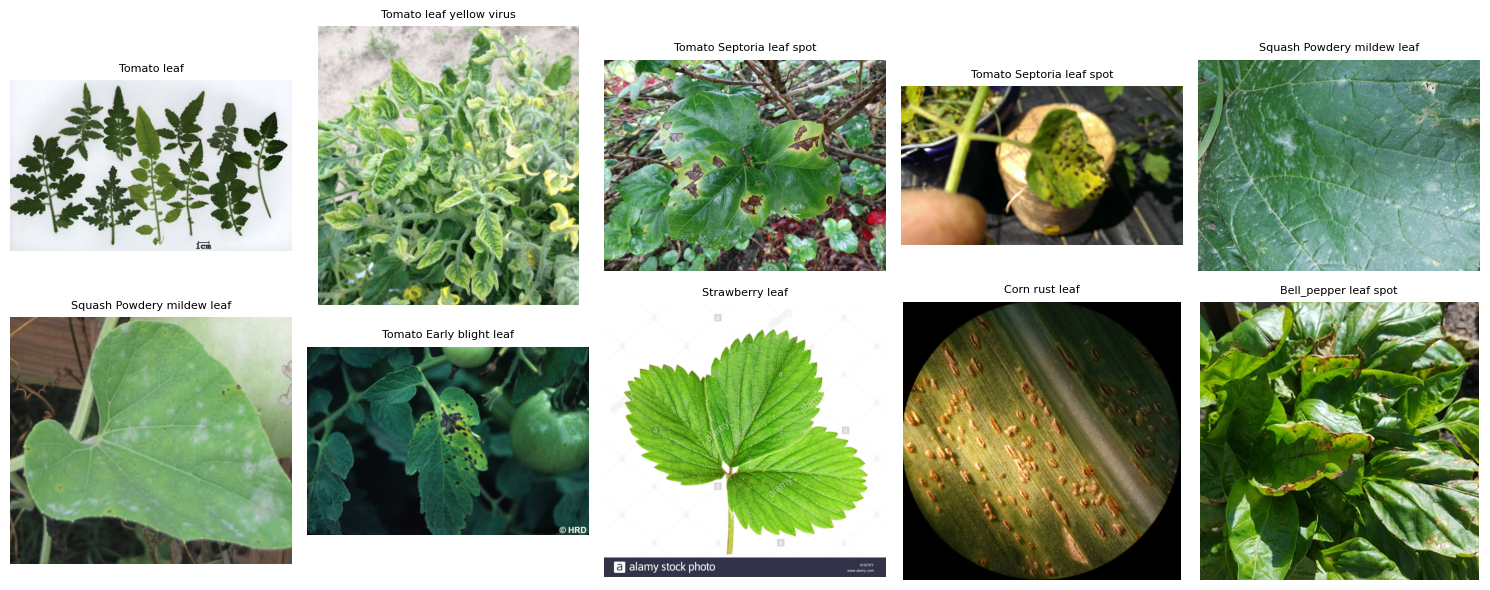

In [5]:
SIZE=CFG['image_size'];MEAN=[0.485,0.456,0.406];STD=[0.229,0.224,0.225]
ImageFile.LOAD_TRUNCATED_IMAGES=False
pv_train_tf=transforms.Compose([transforms.RandomResizedCrop(SIZE,scale=(0.72,1.0)),transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(p=0.2),transforms.RandomRotation(12),
    transforms.ColorJitter(brightness=.18,contrast=.18,saturation=.15,hue=.025),transforms.ToTensor(),transforms.Normalize(MEAN,STD)])
doc_train_tf=transforms.Compose([transforms.RandomResizedCrop(SIZE,scale=(.72,1.0)),transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(12),transforms.ColorJitter(brightness=.20,contrast=.18,saturation=.18,hue=.025),
    transforms.ToTensor(),transforms.Normalize(MEAN,STD)])
eval_tf=transforms.Compose([transforms.Resize(256),transforms.CenterCrop(SIZE),transforms.ToTensor(),transforms.Normalize(MEAN,STD)])
class LeafDataset(Dataset):
    def __init__(self,frame,tf):self.paths=frame.abs_path.tolist();self.y=frame.target.astype(int).tolist();self.tf=tf
    def __len__(self):return len(self.paths)
    def __getitem__(self,i):
        with Image.open(self.paths[i]) as p:img=ImageOps.exif_transpose(p).convert('RGB')
        return self.tf(img),self.y[i]
class MixedDataset(Dataset):
    def __init__(self,parts):self.parts=parts;self.cums=np.cumsum([len(x) for x in parts])
    def __len__(self):return int(self.cums[-1])
    def __getitem__(self,i):
        j=int(np.searchsorted(self.cums,i,side='right'))
        base=0 if j==0 else int(self.cums[j-1]);return self.parts[j][i-base]
W=CFG['workers'];B=CFG['batch'];pin=True
def loader(frame,train=False,tf=None):
    return DataLoader(LeafDataset(frame,tf or (pv_train_tf if train else eval_tf)),batch_size=B,shuffle=train,num_workers=W,pin_memory=pin,persistent_workers=W>0)
pv_train_dl=loader(pv_train,train=True)
pv_val_dl=loader(pv_val)
doc_val_dl=loader(doc_val)
pv_test_dl=loader(pv_official_test)
doc_test_dl=loader(doc_source_test)
mixed=MixedDataset([LeafDataset(pv_train,pv_train_tf),LeafDataset(doc_train,doc_train_tf)])
portion=float(CFG['plantdoc_sample_share']);assert 0<portion<1
weights=np.concatenate([np.full(len(pv_train),(1-portion)/len(pv_train)),np.full(len(doc_train),portion/len(doc_train))])
sampler=WeightedRandomSampler(torch.as_tensor(weights,dtype=torch.double),num_samples=len(pv_train),replacement=True)
adapt_dl=DataLoader(mixed,batch_size=B,sampler=sampler,num_workers=W,pin_memory=pin,persistent_workers=W>0)
# Verify representative images BEFORE running a long experiment.
for name,frame in [('pv_train',pv_train),('pv_val',pv_val),('doc_train',doc_train),('doc_val',doc_val),('doc_test',doc_source_test)]:
    subset=frame.sample(n=min(20,len(frame)),random_state=SEED)
    for p in subset.abs_path:
        with Image.open(p) as im:im.verify()
    print(name,'sample verification passed:',len(subset))
fig,axes=plt.subplots(2,5,figsize=(15,6))
for ax,(_,r) in zip(axes.flat,doc_train.sample(n=min(10,len(doc_train)),random_state=SEED).iterrows()):
    with Image.open(r.abs_path) as im:ax.imshow(ImageOps.exif_transpose(im).convert('RGB'))
    ax.set_title(r.label_original[:28],fontsize=8);ax.axis('off')
fig.tight_layout();fig.savefig(OUT/'examples'/'plantdoc_train_examples.png',dpi=125);plt.show();plt.close(fig)

## 5 — PlantVillage baseline (optional reuse of V1 checkpoint)

To avoid expensive repeated training, set `V1_CHECKPOINT` to an attached Kaggle **input** model path. It must contain the `state_dict` and `classes` from Day31 V1. If absent, train a fresh PV-only MobileNetV3-Small baseline; this creates a fair paired baseline for V2. Select baseline using PV validation **only**. Neither PlantDoc source test nor PV official test is used during selection.

In [6]:
V1_CHECKPOINT=None  # e.g. '/kaggle/input/<your-v1-output>/models/best_mobilenetv3_small.pt'
BASELINE=OUT/'models'/'baseline_pv_best.pt'
def build_model(pretrained=True):
    m=mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.DEFAULT if pretrained else None)
    m.classifier[3]=nn.Linear(m.classifier[3].in_features,len(classes))
    return m.to(DEVICE)
model=build_model(pretrained=(V1_CHECKPOINT is None))
if V1_CHECKPOINT is not None:
    p=Path(V1_CHECKPOINT)
    assert p.is_file(),f'Attached V1 checkpoint not found: {p}'
    blob=torch.load(p,map_location='cpu',weights_only=False)
    assert isinstance(blob,dict) and blob.get('classes')==classes and 'state_dict' in blob,'Incompatible V1 checkpoint'
    model.load_state_dict(blob['state_dict']);model.to(DEVICE)
    torch.save({'state_dict':model.cpu().state_dict(),'classes':classes,'source':str(p),'epoch':blob.get('epoch')},BASELINE)
    model.to(DEVICE)
    print('Reused user-provided V1 checkpoint',p)
else:
    criterion=nn.CrossEntropyLoss(label_smoothing=.04)
    amp=torch.amp.GradScaler('cuda',enabled=True)
    @torch.no_grad()
    def baseline_val():
        model.eval();ys=[];yh=[]
        for x,y in pv_val_dl:
            with torch.autocast('cuda',enabled=True):o=model(x.to(DEVICE)).float()
            ys.extend(y.tolist());yh.extend(o.argmax(1).cpu().tolist())
        return float(f1_score(ys,yh,labels=list(range(len(classes))),average='macro',zero_division=0))
    def baseline_train(opt):
        model.train();total=0;correct=0;loss_sum=0
        for x,y in pv_train_dl:
            x=x.to(DEVICE);y=y.to(DEVICE);opt.zero_grad(set_to_none=True)
            with torch.autocast('cuda',enabled=True):o=model(x);loss=criterion(o,y)
            amp.scale(loss).backward();amp.unscale_(opt);nn.utils.clip_grad_norm_(model.parameters(),5)
            amp.step(opt);amp.update()
            total+=len(y);correct+=int((o.argmax(1)==y).sum());loss_sum+=float(loss.detach())*len(y)
        return loss_sum/total,correct/total
    for par in model.features.parameters():par.requires_grad=False
    opt=torch.optim.AdamW((p for p in model.parameters() if p.requires_grad),lr=1e-3,weight_decay=CFG['weight_decay'])
    history=[];best_f1=-1
    for epoch in range(1,CFG['pv_head_epochs']+CFG['pv_fine_epochs']+1):
        if epoch==CFG['pv_head_epochs']+1:
            for par in model.features.parameters():par.requires_grad=False
            for blk in list(model.features.children())[-5:]:
                for par in blk.parameters():par.requires_grad=True
            opt=torch.optim.AdamW((p for p in model.parameters() if p.requires_grad),lr=CFG['base_lr'],weight_decay=CFG['weight_decay'])
        loss,acc=baseline_train(opt);score=baseline_val()
        history.append({'epoch':epoch,'train_loss':loss,'train_accuracy':acc,'pv_val_macro_f1':score})
        print('PV BASELINE epoch',epoch,'loss',round(loss,4),'acc',round(acc,4),'PV val macroF1',round(score,4),flush=True)
        if score>best_f1:
            best_f1=score
            torch.save({'state_dict':model.state_dict(),'classes':classes,'epoch':epoch,'pv_val_macro_f1':score},BASELINE)
    pd.DataFrame(history).to_csv(OUT/'reports'/'pv_baseline_history.csv',index=False)
assert BASELINE.is_file()
base_state=torch.load(BASELINE,map_location='cpu',weights_only=False)
model.load_state_dict(base_state['state_dict']);model.to(DEVICE)
print('BASELINE READY',BASELINE,round(BASELINE.stat().st_size/1024**2,1),'MiB')

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 87.6MB/s]


PV BASELINE epoch 1 loss 0.8269 acc 0.861 PV val macroF1 0.9096
PV BASELINE epoch 2 loss 0.5956 acc 0.9301 PV val macroF1 0.9441
PV BASELINE epoch 3 loss 0.4755 acc 0.9685 PV val macroF1 0.9732
PV BASELINE epoch 4 loss 0.4271 acc 0.9806 PV val macroF1 0.9763
PV BASELINE epoch 5 loss 0.4022 acc 0.9869 PV val macroF1 0.9831
PV BASELINE epoch 6 loss 0.389 acc 0.9901 PV val macroF1 0.9805
PV BASELINE epoch 7 loss 0.3798 acc 0.9915 PV val macroF1 0.9906
BASELINE READY /kaggle/working/Day31_LeafDoctor_Lite_V2/models/baseline_pv_best.pt 6.1 MiB


## 6 — Domain adaptation with **PlantDoc source train only**

Freeze most pretrained layers, unfreeze final feature blocks + classifier. Train a 60/40 PV/PlantDoc mixture, choose checkpoint on **PlantDoc source-train internal validation macro-F1** with PV validation accuracy as a stability constraint: do not accept a model with PV validation accuracy dropping > 3 percentage points from the baseline. This avoids selecting solely for the easy PV benchmark; it does not guarantee real field safety.

Baseline PV validation: {'n': 5231, 'accuracy': 0.9923532785318295, 'macro_f1': 0.9905967311355193, 'balanced_accuracy': 0.9909509700789471}
ADAPT epoch 1: train loss 0.9786; doc val macroF1 0.5368; PV val acc 0.9876; PV drop 0.0048; saved=True


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


ADAPT epoch 2: train loss 0.6813; doc val macroF1 0.5783; PV val acc 0.9859; PV drop 0.0065; saved=True


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


ADAPT epoch 3: train loss 0.5708; doc val macroF1 0.5657; PV val acc 0.9868; PV drop 0.0055; saved=False


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


... (7 outputs left out)

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


ADAPT epoch 8: train loss 0.4219; doc val macroF1 0.5826; PV val acc 0.9878; PV drop 0.0046; saved=False


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Early stopping after 3 unimproved epochs
Selected adaptation epoch 5 DOC VAL macroF1 0.5963477434930549


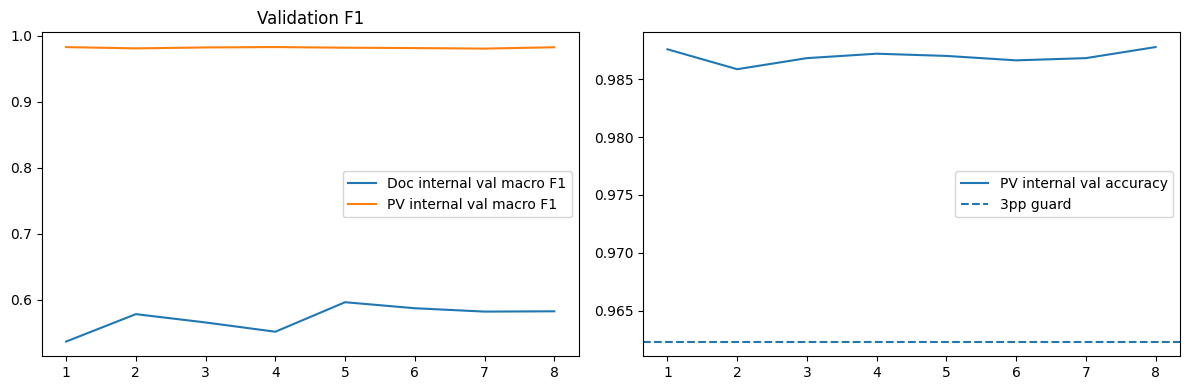

In [7]:
@torch.inference_mode()
def predict_loader(m,dl):
    m.eval();logits=[];ys=[]
    for X,y in dl:
        with torch.autocast('cuda',enabled=True):o=m(X.to(DEVICE)).float().cpu().numpy()
        logits.append(o);ys.append(y.numpy())
    return np.concatenate(logits),np.concatenate(ys)
def scores_for(logits,y,labels=None):
    p=logits.argmax(1)
    if labels is None:labels=list(range(len(classes)))
    return {'n':len(y),'accuracy':float(accuracy_score(y,p)),
            'macro_f1':float(f1_score(y,p,labels=labels,average='macro',zero_division=0)),
            'balanced_accuracy':float(balanced_accuracy_score(y,p))}
# Baseline validation evaluated before adaptation; never inspect test here.
base_pv_l,base_pv_y=predict_loader(model,pv_val_dl)
base_pv_val=scores_for(base_pv_l,base_pv_y)
print('Baseline PV validation:',base_pv_val)
ADAPTED=OUT/'models'/'adapted_best.pt'
criterion=nn.CrossEntropyLoss(label_smoothing=.03)
scaler=torch.amp.GradScaler('cuda',enabled=True)
for p in model.features.parameters():p.requires_grad=False
for block in list(model.features.children())[-6:]:
    for p in block.parameters():p.requires_grad=True
for p in model.classifier.parameters():p.requires_grad=True
opt=torch.optim.AdamW([
    {'params':[p for p in model.features.parameters() if p.requires_grad],'lr':CFG['adapt_lr']*.45},
    {'params':list(model.classifier.parameters()),'lr':CFG['adapt_lr']}],weight_decay=CFG['weight_decay'])
scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(opt,T_max=CFG['adapt_epochs'],eta_min=1e-6)
train_history=[];best_score=-1;best_epoch=0;bad=0
for epoch in range(1,CFG['adapt_epochs']+1):
    model.train();loss_total=0;n=0
    for x,y in adapt_dl:
        x=x.to(DEVICE);y=y.to(DEVICE);opt.zero_grad(set_to_none=True)
        with torch.autocast('cuda',enabled=True):out=model(x);loss=criterion(out,y)
        scaler.scale(loss).backward();scaler.unscale_(opt);nn.utils.clip_grad_norm_(model.parameters(),5)
        scaler.step(opt);scaler.update();loss_total+=float(loss.detach())*len(y);n+=len(y)
    doc_l,doc_y=predict_loader(model,doc_val_dl)
    pv_l,pv_y=predict_loader(model,pv_val_dl)
    doc_score=scores_for(doc_l,doc_y,labels=sorted(set(doc_y.tolist())))
    pv_score=scores_for(pv_l,pv_y)
    pv_drop=base_pv_val['accuracy']-pv_score['accuracy']
    eligible=pv_drop<=.03
    improved=eligible and doc_score['macro_f1']>best_score+1e-5
    if improved:
        best_score=doc_score['macro_f1'];best_epoch=epoch;bad=0
        torch.save({'state_dict':model.state_dict(),'classes':classes,'epoch':epoch,'doc_val_macro_f1':best_score,
                    'pv_val_accuracy':pv_score['accuracy'],'mapping':MAPPING,'seed':SEED},ADAPTED)
    else:bad+=1
    train_history.append({'epoch':epoch,'adapt_train_loss':loss_total/n,
        'doc_val_accuracy':doc_score['accuracy'],'doc_val_macro_f1':doc_score['macro_f1'],
        'pv_val_accuracy':pv_score['accuracy'],'pv_val_macro_f1':pv_score['macro_f1'],
        'pv_accuracy_drop':pv_drop,'selection_eligible':eligible,'selected':improved})
    print(f'ADAPT epoch {epoch}: train loss {loss_total/n:.4f}; doc val macroF1 {doc_score["macro_f1"]:.4f}; PV val acc {pv_score["accuracy"]:.4f}; PV drop {pv_drop:.4f}; saved={improved}',flush=True)
    scheduler.step()
    if bad>=CFG['adapt_patience']:
        print('Early stopping after',bad,'unimproved epochs');break
pd.DataFrame(train_history).to_csv(OUT/'reports'/'adaptation_history.csv',index=False)
if not ADAPTED.is_file():
    print('WARNING: no adaptation checkpoint met PV validation guard. Fallback to PV baseline. This is a documented negative result.')
    shutil.copy2(BASELINE,ADAPTED)
    best_epoch=0
else:
    print('Selected adaptation epoch',best_epoch,'DOC VAL macroF1',best_score)
hist=pd.DataFrame(train_history)
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(hist.epoch,hist.doc_val_macro_f1,label='Doc internal val macro F1')
axes[0].plot(hist.epoch,hist.pv_val_macro_f1,label='PV internal val macro F1');axes[0].legend();axes[0].set_title('Validation F1')
axes[1].plot(hist.epoch,hist.pv_val_accuracy,label='PV internal val accuracy');axes[1].axhline(base_pv_val['accuracy']-.03,linestyle='--',label='3pp guard');axes[1].legend()
fig.tight_layout();fig.savefig(OUT/'plots'/'adaptation_learning_curves.png',dpi=150);plt.show();plt.close(fig)

## 7 — Lock checkpoints; *one final* PlantDoc test and official PV test evaluation

All training, checkpoint selection and learning-rate decisions are over. Only now evaluate **both** baseline and adapted model on *the same* mapped PlantDoc source test and PlantVillage official test. The PlantDoc test subset mapping is locked in cell 4; unmapped labels remain excluded and counted. Baseline evaluation now is legitimate for a paired comparison; do not train further after reading results.

pv_baseline plantdoc_test_mapped {'n': 182, 'accuracy': 0.26373626373626374, 'macro_f1': 0.24545243144629775, 'balanced_accuracy': 0.2745523415977961, 'model': 'pv_baseline', 'dataset': 'plantdoc_test_mapped', 'n_classes_in_ground_truth': 22}


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


pv_baseline plantvillage_official_test {'n': 10709, 'accuracy': 0.9858997105238584, 'macro_f1': 0.9816351526933715, 'balanced_accuracy': 0.9801955543498624, 'model': 'pv_baseline', 'dataset': 'plantvillage_official_test', 'n_classes_in_ground_truth': 38}


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


field_adapted plantdoc_test_mapped {'n': 182, 'accuracy': 0.6208791208791209, 'macro_f1': 0.617623225587622, 'balanced_accuracy': 0.6127279286370195, 'model': 'field_adapted', 'dataset': 'plantdoc_test_mapped', 'n_classes_in_ground_truth': 22}
field_adapted plantvillage_official_test {'n': 10709, 'accuracy': 0.982351293304697, 'macro_f1': 0.9756507464756442, 'balanced_accuracy': 0.9732736737960008, 'model': 'field_adapted', 'dataset': 'plantvillage_official_test', 'n_classes_in_ground_truth': 38}


,n,accuracy,macro_f1,balanced_accuracy,model,dataset,n_classes_in_ground_truth
0,182,0.263736,0.245452,0.274552,pv_baseline,plantdoc_test_mapped,22
1,10709,0.985900,0.981635,0.980196,pv_baseline,plantvillage_official_test,38
2,182,0.620879,0.617623,0.612728,field_adapted,plantdoc_test_mapped,22
3,10709,0.982351,0.975651,0.973274,field_adapted,plantvillage_official_test,38


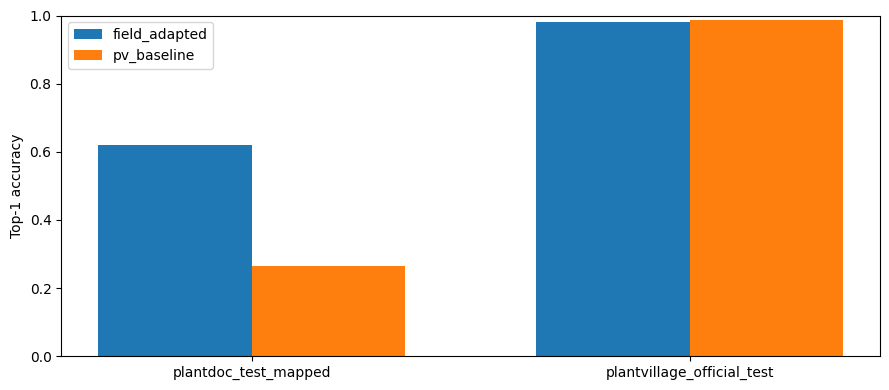

398

In [8]:
def build_from_checkpoint(p):
    m=build_model(pretrained=False)
    obj=torch.load(p,map_location='cpu',weights_only=False)
    assert obj['classes']==classes
    m.load_state_dict(obj['state_dict']);m.eval();return m
baseline_model=build_from_checkpoint(BASELINE)
adapted_model=build_from_checkpoint(ADAPTED)
# Evaluate both models on two held-out sets; no model selection after this block.
results=[];pred_tables=[]
for model_name,m in [('pv_baseline',baseline_model),('field_adapted',adapted_model)]:
    for dataset_name,dl,frame in [('plantdoc_test_mapped',doc_test_dl,doc_source_test),('plantvillage_official_test',pv_test_dl,pv_official_test)]:
        logits,y=predict_loader(m,dl);pred=logits.argmax(1)
        observed=sorted(set(y.tolist()))
        metric=scores_for(logits,y,labels=observed if dataset_name.startswith('plantdoc') else list(range(len(classes))))
        metric.update({'model':model_name,'dataset':dataset_name,'n_classes_in_ground_truth':len(observed)})
        results.append(metric)
        pred_tables.append(pd.DataFrame({'source':dataset_name,'model':model_name,'image_path':frame.abs_path.to_numpy(),
            'true_id':y,'true_class':[classes[int(i)] for i in y],
            'pred_id':pred,'pred_class':[classes[int(i)] for i in pred],'correct':pred==y}))
        pd.DataFrame(classification_report(y,pred,labels=list(range(len(classes))),target_names=classes,
                         output_dict=True,zero_division=0)).T.to_csv(OUT/'reports'/f'{model_name}_{dataset_name}_perclass.csv')
        cm=confusion_matrix(y,pred,labels=list(range(len(classes))))
        pd.DataFrame(cm,index=classes,columns=classes).to_csv(OUT/'reports'/f'{model_name}_{dataset_name}_confusion.csv')
        print(model_name,dataset_name,metric)
metric_df=pd.DataFrame(results)
metric_df.to_csv(OUT/'reports'/'paired_test_metrics.csv',index=False)
pd.concat(pred_tables,ignore_index=True).to_csv(OUT/'predictions'/'paired_test_predictions.csv',index=False)
display(metric_df)
fig,ax=plt.subplots(figsize=(9,4))
xx=np.arange(2);wide=metric_df.pivot(index='dataset',columns='model',values='accuracy')
for j,name in enumerate(wide.columns):ax.bar(xx+(j-.5)*.35,wide[name].to_numpy(),width=.35,label=name)
ax.set_xticks(xx,wide.index.tolist());ax.set_ylim(0,1);ax.set_ylabel('Top-1 accuracy');ax.legend()
fig.tight_layout();fig.savefig(OUT/'plots'/'paired_test_accuracy.png',dpi=160);plt.show();plt.close(fig)
(OUT/'reports'/'comparability_note.txt').write_text(
    'PlantDoc paired comparison uses exactly the same mapped test samples for both checkpoints. '
    'The historical V1 26.06% was on a different mapped subset (165 images); do not compare it directly with current V2 scores. '
    'PlantDoc full test contains unaligned categories, so mapped-subset metrics are not a full PlantDoc benchmark. '
    'This notebook does not use any final test score for checkpoint selection.\n',encoding='utf8')

## 8 — Failure analysis, confidence disclaimer, and example inference

Identify wrong predictions and class confusion without changing the model. Softmax is a score, not clinically/agronomically calibrated confidence. Fixed 0.80 illustrative uncertainty threshold, **not tuned on external test**. New unknown conditions can still get high confidence. No pesticide advice.

Mapped PlantDoc test errors: 69 / 182


true_class                                          pred_class                                        
Tomato___Bacterial_spot                             Tomato___Septoria_leaf_spot                           4
Potato___Early_blight                               Potato___Late_blight                                  3
Pepper,_bell___Bacterial_spot                       Tomato___Bacterial_spot                               2
Tomato___Bacterial_spot                             Pepper,_bell___Bacterial_spot                         2
Pepper,_bell___Bacterial_spot                       Tomato___Septoria_leaf_spot                           2
Apple___healthy                                     Apple___Apple_scab                                    2
Tomato___Septoria_leaf_spot                         Tomato___Early_blight                                 2
Tomato___Late_blight                                Tomato___Early_blight                                 2
                                 

{
  "status": "preliminary screen",
  "predicted_class": "Apple___healthy",
  "score_not_calibrated_probability": 0.8289096355438232,
  "top_k": [
    {
      "class": "Apple___healthy",
      "score": 0.8289096355438232
    },
    {
      "class": "Peach___healthy",
      "score": 0.06268234550952911
    },
    {
      "class": "Apple___Cedar_apple_rust",
      "score": 0.02786950394511223
    }
  ],
  "disclaimer": "Research-only visual screening. Not a validated field diagnosis. Unknown conditions may yield misleading high confidence. Seek agronomic expert review."
}


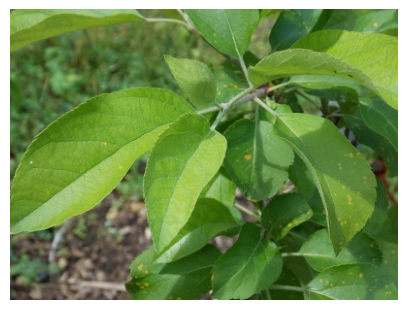

In [9]:
paired=pd.concat(pred_tables,ignore_index=True)
field_errors=paired[(paired.source=='plantdoc_test_mapped')&(paired.model=='field_adapted')&(~paired.correct)]
print('Mapped PlantDoc test errors:',len(field_errors),'/',len(doc_source_test))
display(field_errors.groupby(['true_class','pred_class']).size().sort_values(ascending=False).head(20))
@torch.inference_mode()
def screen_leaf_photo(path_or_image,top_k=3):
    if isinstance(path_or_image,(str,Path)):
        with Image.open(path_or_image) as src:im=ImageOps.exif_transpose(src).convert('RGB')
    elif isinstance(path_or_image,Image.Image):im=ImageOps.exif_transpose(path_or_image).convert('RGB')
    else:raise TypeError('Expected PIL Image or image path')
    adapted_model.eval()
    with torch.autocast('cuda',enabled=True):logits=adapted_model(eval_tf(im).unsqueeze(0).to(DEVICE)).float().cpu()[0]
    probs=torch.softmax(logits,0).numpy();ids=np.argsort(-probs)[:max(1,min(int(top_k),38))]
    return {'status':'preliminary screen' if probs[ids[0]]>=.8 else 'uncertain — expert review',
        'predicted_class':classes[int(ids[0])],'score_not_calibrated_probability':float(probs[ids[0]]),
        'top_k':[{'class':classes[int(i)],'score':float(probs[i])} for i in ids],
        'disclaimer':'Research-only visual screening. Not a validated field diagnosis. Unknown conditions may yield misleading high confidence. Seek agronomic expert review.'}
# Choose deterministic source TRAIN example for illustration, never a cherry-picked test success.
example=doc_train.iloc[0]
print(json.dumps(screen_leaf_photo(example.abs_path),indent=2))
with Image.open(example.abs_path) as im:
    fig,ax=plt.subplots(figsize=(5,5));ax.imshow(ImageOps.exif_transpose(im).convert('RGB'));ax.axis('off')
    fig.savefig(OUT/'examples'/'example_inference_image.png',dpi=140);plt.show();plt.close(fig)

## 9 — Model card, provenance, configuration, inference recipe

Outputs are generated **only from executed model checkpoints**. Document the domain-transfer limitations, explicit weak label mappings, excluded classes and missing evaluation on truly new farms. The model files are in the output archive, not in a redistributed dataset.

In [10]:
final_metrics={r['dataset']+'__'+r['model']:r for r in results}
card={'project':'Day 31/100 — LeafDoctor Lite V2 field adaptation','status':'RESEARCH_BASELINE_NOT_FIELD_VALIDATED',
      'method':'PlantVillage baseline MobileNetV3-Small then mixture fine-tuning on PV train + mapped PlantDoc source train',
      'pv_classes':38,'plantdoc_test_mapped_count':len(doc_source_test),
       'conflict_quarantine':quarantine_summary,'plantdoc_test_total':SPLITS['doc_test_full'],
      'model_selection':'PlantDoc source-train internal validation macro F1 with PV val accuracy no worse than baseline by >3pp',
      'selected_adapt_epoch':best_epoch,'paired_final_metrics':final_metrics,'seed':SEED,
      'label_mapping':MAPPING,'weak_healthy_proxies':sorted(WEAK),
      'excluded_labels':sorted(set(doc.loc[doc.is_labeled_image&(~doc.supported),'label_original'])),
      'limitations':['PlantDoc test mapping covers only a subset, not complete field disease categories',
          'Some generic leaf labels are weak healthy proxies',
          'Label mapping must be reviewed with agronomy experts',
          'Group split by identical bytes does not exclude perceptual near duplicates or identical plants',
          'PlantDoc exact-byte contradictory label groups excluded from all PlantDoc splits',
           'Only two publicly available image datasets; no geographically independent farm validation',
          'Distribution shift, annotation noise and confidence miscalibration',
          'No diagnoses, treatment or pesticide recommendations'],
      'claim':'Paired research validation only; not guaranteed field accuracy'}
(OUT/'models'/'MODEL_CARD.json').write_text(json.dumps(card,ensure_ascii=False,indent=2))
recipe={'checkpoint':'models/adapted_best.pt','fallback':'models/baseline_pv_best.pt',
  'architecture':'torchvision.mobilenet_v3_small','class_names':classes,
  'input':'RGB image','resize_short_edge':256,'center_crop':SIZE,'mean':MEAN,'std':STD,
  'output':'38 softmax class scores, uncalibrated for external field deployment',
  'confidence_example_threshold':0.80,'confidence_threshold_tuned_on_test':False}
(OUT/'models'/'inference_recipe.json').write_text(json.dumps(recipe,ensure_ascii=False,indent=2))
manifest={'generated_utc':datetime.now(timezone.utc).isoformat(),'kaggle_input':str(INPUT),
 'sources':{'PlantVillage':'https://huggingface.co/datasets/mohanty/PlantVillage',
            'PlantDoc':'https://github.com/pratikkayal/PlantDoc-Dataset'},
 'license_notes':'Check license terms at original sources before redistribution. Original images excluded from output archive.',
 'split_counts':SPLITS,'conflict_quarantine':quarantine_summary,'config':CFG,'python':sys.version,'torch':torch.__version__,'torchvision':torchvision.__version__,
 'exact_hash_leakage_checked':True,'perceptual_duplicates_checked':False,
 'V1_historical_external_accuracy':0.2606060606060606,
 'V1_historical_subset_size':165,
 'V1_not_directly_comparable_with_changed_mapping':True}
(OUT/'metadata'/'dataset_provenance.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2))
(OUT/'metadata'/'config.json').write_text(json.dumps(CFG,indent=2))
(OUT/'README.md').write_text("""# LeafDoctor Lite V2 — Day 31/100

Research-only plant leaf image screening. Not diagnosis or treatment advice.

- Source: PlantVillage training and source-train mapped PlantDoc, no final-test data used in optimization.
- Baseline and adapted checkpoint evaluated on the same target test mapping, at the END of all training.
- Baseline V1 historical 26.06% (165 images) is NOT directly comparable with this notebook's potentially changed mapping.
- See models/MODEL_CARD.json, models/inference_recipe.json, metadata/dataset_provenance.json and reports/paired_test_metrics.csv.
- Raw training/testing images are intentionally excluded from output ZIP.
""",encoding='utf8')
try:
    if CFG['enable_torchscript_export']:
        traced=torch.jit.trace(adapted_model.eval(),torch.zeros(1,3,SIZE,SIZE,device=DEVICE))
        traced.save(str(OUT/'models'/'adapted_mobilenetv3_scripted.pt'))
        print('TorchScript export PASS')
except Exception as e:
    (OUT/'reports'/'torchscript_export_error.txt').write_text(repr(e))
    print('TorchScript optional export failed:',repr(e))
print('Reports and model card written')

TorchScript export PASS
Reports and model card written


## 10 — CRC-verified results ZIP and acceptance report

Output under `/kaggle/working/Day31_LeafDoctor_Lite_V2_1_Results.zip`. **Run All → Save Version**. Model metrics remain blank until real Kaggle execution. Source training images are excluded from the ZIP. Archive contents include baseline+adapted model, split/mapping audits, model card, inference recipe, metrics, errors, plots and provenance.

In [11]:
ARCHIVE=Path('/kaggle/working/Day31_LeafDoctor_Lite_V2_1_Results.zip')
assert BASELINE.exists() and ADAPTED.exists()
assert (OUT/'reports'/'paired_test_metrics.csv').exists()
with zipfile.ZipFile(ARCHIVE,'w',zipfile.ZIP_DEFLATED,compresslevel=5,allowZip64=True) as z:
    for f in sorted(OUT.rglob('*')):
        if f.is_file():z.write(f,f.relative_to(OUT).as_posix())
with zipfile.ZipFile(ARCHIVE) as z:
    corrupt=z.testzip();assert corrupt is None,f'CRC failure: {corrupt}'
    print('ZIP CRC PASS:',len(z.namelist()),'files,',round(ARCHIVE.stat().st_size/1024**2,2),'MiB')
print('RESULTS',ARCHIVE)
print('Day31 V2 training+evaluation complete; report observed test metrics accurately, even if lower than baseline.')

ZIP CRC PASS: 42 files, 25.75 MiB
RESULTS /kaggle/working/Day31_LeafDoctor_Lite_V2_1_Results.zip
Day31 V2 training+evaluation complete; report observed test metrics accurately, even if lower than baseline.


## Final checklist

- [ ] Dataset index and original PlantDoc path mapping checked.
- [ ] Mapping determined before training or external test inspection; weak healthy proxies flagged.
- [ ] No PlantDoc source-test photos or labels used for training, validation or checkpoint selection.
- [ ] Exact source-test overlaps removed from source train; content-conflicting source labels quarantined and audited; test cohort exclusions disclosed.
- [ ] PV baseline checkpoint available (loaded from attached V1 or trained from pretrained ImageNet weights).
- [ ] Adaptation checkpoint selected only using PV/PlantDoc train-derived validation.
- [ ] Both models evaluated on **same** final mapped PlantDoc source test and PV official test.
- [ ] If results worsen, keep and report negative result. Do not alter mapping/test selection based on external scores.
- [ ] Model card, reports, PNG plots, demo, prediction CSV, inference recipe, complete ZIP CRC verified.

**Interpretation:** A higher PlantDoc subset score is evidence of improvement on these limited categories and images, not proof of field deployment readiness. A fairer agricultural field benchmark needs fresh data and independent expertise.